In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv("../data/tcs_features.csv", index_col="Date", parse_dates=True)
print(df.shape)
df.columns.tolist()

(1627, 19)


['Open',
 'High',
 'Low',
 'Close',
 'Volume',
 'Return',
 'Return_lag1',
 'Return_lag2',
 'Return_lag3',
 'Return_lag5',
 'SMA_10',
 'SMA_20',
 'SMA_50',
 'EMA_12',
 'Volatility_10',
 'Volume_change',
 'RSI_14',
 'Target_price',
 'Target_up']

In [2]:
target_cols = ["Target_price", "Target_up"]
feature_cols = [c for c in df.columns if c not in target_cols]

X = df[feature_cols]
y = df["Target_price"]

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.index[0].date(), "to", X_train.index[-1].date())
print("Test: ", X_test.index[0].date(), "to", X_test.index[-1].date())

Train: 2020-03-12 to 2025-06-16
Test:  2025-06-17 to 2026-10-09


In [3]:
def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name}: RMSE = {rmse:.2f}, MAE = {mae:.2f}")

baseline_pred = X_test["Close"]
evaluate("Naive baseline", y_test, baseline_pred)

Naive baseline: RMSE = 42.91, MAE = 30.53


In [4]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

evaluate("Linear Regression", y_test, lr_pred)

Linear Regression: RMSE = 43.45, MAE = 31.19


In [5]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

evaluate("Random Forest", y_test, rf_pred)

Random Forest: RMSE = 63.56, MAE = 48.03


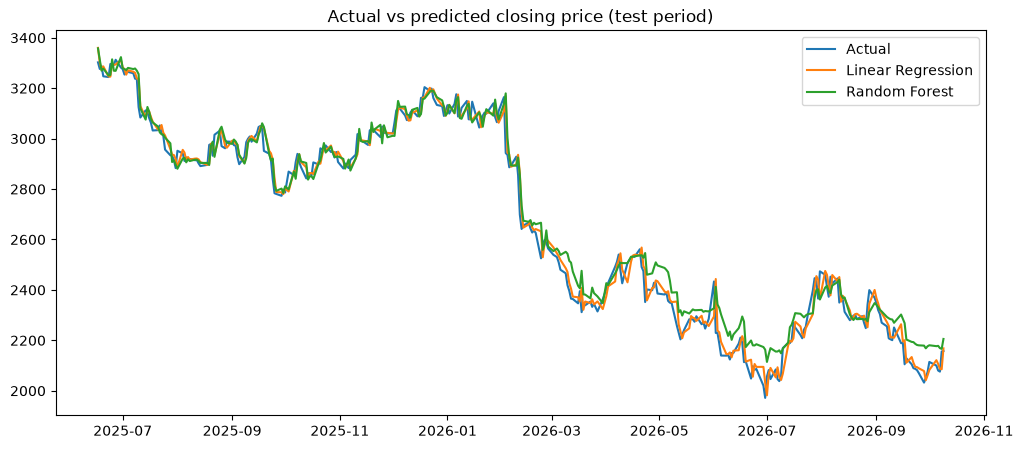

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, lr_pred, label="Linear Regression")
plt.plot(y_test.index, rf_pred, label="Random Forest")
plt.legend()
plt.title("Actual vs predicted closing price (test period)")
plt.show()

In [7]:
evaluate("Naive baseline", y_test, X_test["Close"])
evaluate("Linear Regression", y_test, lr_pred)
evaluate("Random Forest", y_test, rf_pred)

Naive baseline: RMSE = 42.91, MAE = 30.53
Linear Regression: RMSE = 43.45, MAE = 31.19
Random Forest: RMSE = 63.56, MAE = 48.03


In [10]:
# Scale-free features
feat = pd.DataFrame(index=df.index)
for c in ["Return", "Return_lag1", "Return_lag2", "Return_lag3",
          "Return_lag5", "Volatility_10", "Volume_change", "RSI_14"]:
    feat[c] = df[c]
for c in ["SMA_10", "SMA_20", "SMA_50", "EMA_12"]:
    feat[f"Close_vs_{c}"] = df["Close"] / df[c] - 1

# Target: tomorrow's return
y_ret = df["Target_price"] / df["Close"] - 1

split = int(len(df) * 0.8)
Xr_train, Xr_test = feat.iloc[:split], feat.iloc[split:]
yr_train = y_ret.iloc[:split]

from sklearn.ensemble import RandomForestRegressor
rf2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                            random_state=42, n_jobs=-1)
rf2.fit(Xr_train, yr_train)

# Convert the predicted return back into a price
rf2_pred = X_test["Close"] * (1 + rf2.predict(Xr_test))

evaluate("Naive baseline", y_test, X_test["Close"])
evaluate("RF on returns", y_test, rf2_pred)

Naive baseline: RMSE = 42.91, MAE = 30.53
RF on returns: RMSE = 44.14, MAE = 32.45


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

y_dir = df["Target_up"]
yd_train, yd_test = y_dir.iloc[:split], y_dir.iloc[split:]

clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                             random_state=42, n_jobs=-1)
clf.fit(Xr_train, yd_train)
pred = clf.predict(Xr_test)

print("Model accuracy:", round(accuracy_score(yd_test, pred), 3))
print("Always predict 'up':", round(yd_test.mean(), 3))

Model accuracy: 0.472
Always predict 'up': 0.433


In [12]:
print("Always predict 'down':", round(1 - yd_test.mean(), 3))

Always predict 'down': 0.567


In [13]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                   subsample=0.8, random_state=42)
xgb.fit(Xr_train, yr_train)
xgb_pred = X_test["Close"] * (1 + xgb.predict(Xr_test))

evaluate("Naive baseline", y_test, X_test["Close"])
evaluate("XGBoost on returns", y_test, xgb_pred)

Naive baseline: RMSE = 42.91, MAE = 30.53
XGBoost on returns: RMSE = 44.15, MAE = 32.31


In [14]:
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor

tscv = TimeSeriesSplit(n_splits=5)
rows = []

for i, (tr, te) in enumerate(tscv.split(feat), 1):
    close_te = df["Close"].iloc[te]
    y_true = df["Target_price"].iloc[te]

    model = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                         subsample=0.8, random_state=42)
    model.fit(feat.iloc[tr], y_ret.iloc[tr])
    pred = close_te * (1 + model.predict(feat.iloc[te]))

    rows.append({
        "Fold": i,
        "Test period": f"{close_te.index[0].date()} to {close_te.index[-1].date()}",
        "Baseline MAE": round(mean_absolute_error(y_true, close_te), 2),
        "XGBoost MAE": round(mean_absolute_error(y_true, pred), 2),
    })

results = pd.DataFrame(rows)
results

,Fold,Test period,Baseline MAE,XGBoost MAE
0,1,2021-04-16 to 2022-05-19,29.39,34.84
1,2,2022-05-20 to 2023-06-21,27.74,30.81
2,3,2023-06-22 to 2024-07-31,31.85,32.97
3,4,2024-08-01 to 2025-09-03,32.45,36.40
4,5,2025-09-04 to 2026-10-09,31.95,33.95
